### Sub-graphs 
- Sub-graphs allow to create and manage different states in different parts of the graph 
- This particularly useful for multi-agent systems with teams of agents that each have their own state
- A toy example: 
  - I have a system that accepts log 
  - It performs two separate sub-tasks by different agents(summarize logs,find failure modes)
  - I want to perform these two operations in two different sub-graphs 
- The most critical thing to understand is how the graphs communicate! 
- In short communication is done with *__over-lapping keys__* 
  - The sub-graphs can access `docs` from parent 
  - The parent can access `summary/failure_report` from sub-graph
  
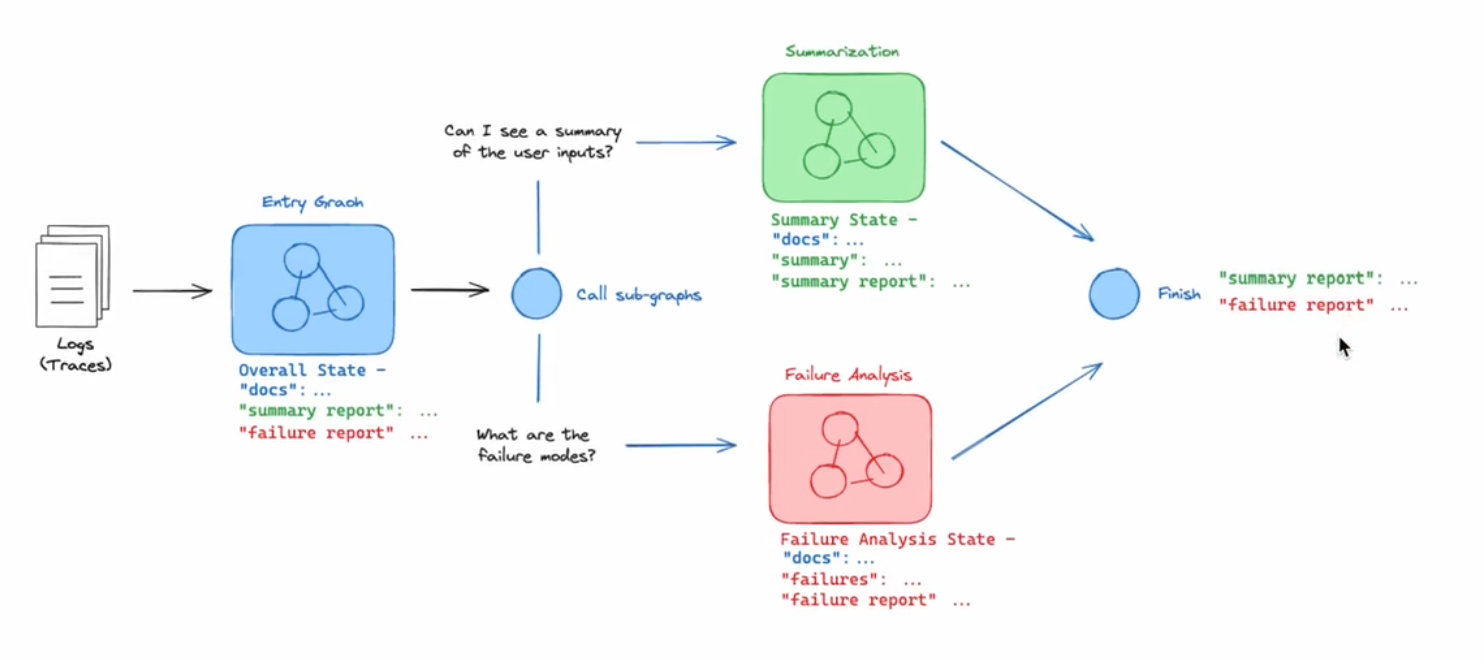

In [1]:
from operator import add
from typing import Annotated, Literal, TypedDict

from IPython.display import Image, display
from langgraph.graph import END, START, StateGraph


In [2]:
class Log(TypedDict):
    _id: str
    question: str
    docs: list | None
    answer: str
    grade: int | None
    grader: str | None
    feedback: str | None

#### Sub-graphs

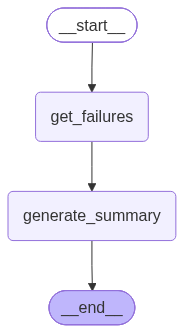

In [14]:
# INFO Failure Analysis Sub-graph
class FailureAnalysisState(TypedDict):
    cleaned_log: list[Log]
    failures: list[Log]
    fa_summary: str
    processed_logs: list[str]


class FailureAnalysisOutputState(TypedDict):
    fa_summary: str
    processed_logs: list[str]


def get_failures(state):
    """Get Logs that cantain a failure"""
    cleaned_logs = state["cleaned_logs"]
    failures = [log for log in cleaned_logs if "grade" in log]
    return {"failures": failures}


def generate_summary(state):
    """Generate summary of failures"""
    failures = state["failures"]
    # INFO Add fxn fa_summary =summarize(failures)
    fa_summary = "poor quality retieval of chroma documentation"
    return {
        "fa_summary": fa_summary,
        "processed_logs": [
            f"failure-analysis-on-log-{failure['id']}" for failure in failures
        ],
    }


fa_builder = StateGraph(
    state_schema=FailureAnalysisState, output_schema=FailureAnalysisOutputState
)
fa_builder.add_node("get_failures", get_failures)
fa_builder.add_node("generate_summary", generate_summary)
fa_builder.add_edge(START, "get_failures")
fa_builder.add_edge("get_failures", "generate_summary")
fa_builder.add_edge("get_failures", END)
fa_graph = fa_builder.compile()
display(Image(fa_graph.get_graph().draw_mermaid_png()))


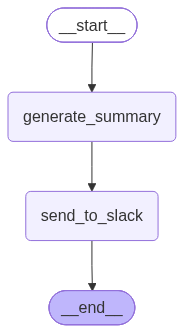

In [15]:
# INFO Summarization subgraph
class QuestionSummarization(TypedDict):
    cleaned_logs: list[str]
    qs_summary: str
    report: str
    processed_logs: list[str]


class QuestionSummaryOutputState(TypedDict):
    report: str
    processed_logs: list[str]


def generate_summary(state):
    cleaned_logs = state["cleaned_logs"]
    summary = "Questions focused on usage of ChatOllama and Chroma vector store"
    return {
        "qs_summary": summary,
        "processed_logs": [f"summary-on-log-{log['id']}" for log in cleaned_logs],
    }


def send_to_slack(state):
    qs_summary = state["qs_summary"]
    report = "foo bar baz"
    return {"report": report}


qs_builder = StateGraph(QuestionSummarization, output_schema=QuestionSummaryOutputState)
qs_builder.add_node("generate_summary", generate_summary)
qs_builder.add_node("send_to_slack", send_to_slack)
qs_builder.add_edge(START, "generate_summary")
qs_builder.add_edge("generate_summary", "send_to_slack")
qs_builder.add_edge("send_to_slack", END)
qs_graph = qs_builder.compile()
display(Image(qs_graph.get_graph().draw_mermaid_png()))


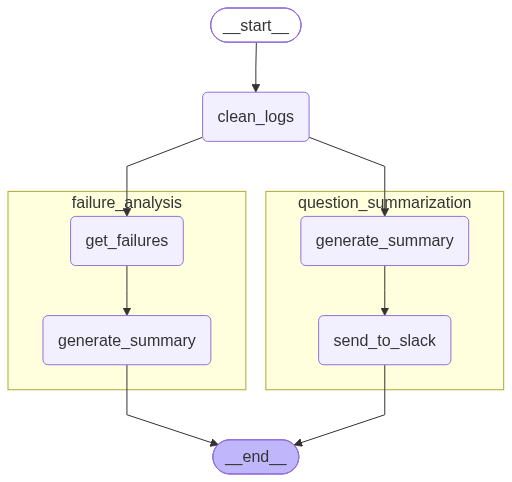

In [16]:
class EntryGraphState(TypedDict):
    raw_logs: list[Log]
    cleaned_logs: Annotated[list[Log], add]
    fa_summary: str
    report: str
    processed_logs: Annotated[list[int], add]


def clean_logs(state):
    raw_logs = state["raw_logs"]
    cleaned_logs = raw_logs
    return {"cleaned_logs": cleaned_logs}


entry_builder = StateGraph(EntryGraphState)
entry_builder.add_node("clean_logs", clean_logs)
entry_builder.add_node("question_summarization", qs_builder.compile())
entry_builder.add_node("failure_analysis", fa_builder.compile())
entry_builder.add_edge(START, "clean_logs")
entry_builder.add_edge("clean_logs", "question_summarization")
entry_builder.add_edge("clean_logs", "failure_analysis")
entry_builder.add_edge("question_summarization", END)
entry_builder.add_edge("failure_analysis", END)
graph = entry_builder.compile()
display(Image(graph.get_graph(xray=True).draw_mermaid_png()))
